# Final screenshots and review of the dashboard

**Data sources:** the dashboard in `../dashboard/` and the results of `build_dashboard.ipynb` (`build_dashboard_output/`) and `browser_checks.ipynb` (`browser_checks_output/`).
**Date:** 2026-11-06
**Authors:** Group 3, Presentation and Visualization (Infovis2627)
**Description:** Task 6.8. Takes the screenshots of both screens for the Part 6 document (`../images/`) and reviews the four checklists of the course skills: DRACO, data-viz best practices, accessible notebooks and WCAG 2.2 AA + COGA. Each item gets a result and its evidence; items not met are listed for the students, who approve the review.

---

## Contents

1. [Data loading](#1.-Data-loading)
2. [Initial exploration](#2.-Initial-exploration)
3. [Cleaning and preparation](#3.-Cleaning-and-preparation)
4. [Analysis: the four checklists](#4.-Analysis:-the-four-checklists)
5. [Accessible visualisation: screenshots](#5.-Accessible-visualisation:-screenshots)
6. [Export](#6.-Export)
7. [Conclusions](#Conclusions)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import json
import re
import sys
from importlib.metadata import version
from pathlib import Path

import pandas as pd
import nbformat
from playwright.async_api import async_playwright   # if missing: pip install playwright, then: playwright install chromium

CODE_DIR = Path('.')
DASHBOARD_DIR = Path('../dashboard').resolve()
IMAGES_DIR = Path('../images')
OUTPUT_DIR = Path('final_review_output')
IMAGES_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
NOTEBOOKS = ['build_dashboard.ipynb', 'browser_checks.ipynb']

print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| nbformat', nbformat.__version__,
      '| playwright', version('playwright'))

Python 3.13.18 | pandas 3.0.5 | nbformat 5.11.1 | playwright 1.63.0


## 1. Data loading

The results of the two notebooks that build and test the dashboard.

In [2]:
# ── Results of the other notebooks ───────────────────────────────────────────
draco = pd.read_csv('build_dashboard_output/draco_checks.csv')
values = pd.read_csv('build_dashboard_output/chart_value_checks.csv')
sizes = pd.read_csv('build_dashboard_output/chart_size_checks.csv')
export = pd.read_csv('build_dashboard_output/export_checks.csv')
first_load = pd.read_csv('browser_checks_output/first_load_checks.csv')
interactions = pd.read_csv('browser_checks_output/interaction_checks.csv')
keyboard = pd.read_csv('browser_checks_output/keyboard_checks.csv')
alternatives = pd.read_csv('browser_checks_output/text_alternative_checks.csv')
operability = pd.read_csv('browser_checks_output/wcag_operability_review.csv')
wcag_other = pd.read_csv('browser_checks_output/wcag_other_items_review.csv')
text_audit = pd.read_csv('browser_checks_output/contrast_and_text_size.csv')
layout = pd.read_csv('browser_checks_output/zoom_and_tablet_checks.csv')
pd.DataFrame([(name, len(table)) for name, table in [('DRACO rule checks', draco), ('chart value renders', values),
              ('chart size checks', sizes), ('export checks', export), ('first-load checks', first_load),
              ('interaction checks', interactions), ('keyboard checks', keyboard), ('text alternative checks', alternatives),
              ('WCAG operability items', operability), ('other WCAG items', wcag_other), ('texts measured', text_audit),
              ('zoom and tablet cases', layout)]], columns=['result file', 'rows'])

,result file,rows
0,DRACO rule checks,197
1,chart value renders,120
2,chart size checks,10
3,export checks,8
4,first-load checks,2
5,interaction checks,32
6,keyboard checks,37
7,text alternative checks,18
8,WCAG operability items,20
9,other WCAG items,27


## 2. Initial exploration

How many checks pass in each file, before the review.

In [3]:
# ── Pass rate of every check file ─────────────────────────────────────────────
pass_rates = pd.DataFrame([
    ('DRACO hard rules', draco['passes'].mean()),
    ('values drawn = pandas', values['same values'].mean()),
    ('charts fit their space', sizes['fits'].mean()),
    ('specs.js and data.js = notebook', export['same as in the notebook'].mean()),
    ('interactions', interactions['passes'].mean()),
    ('keyboard', keyboard['passes'].mean()),
    ('text alternatives and tables', alternatives['passes'].mean()),
    ('text contrast (WCAG AA)', text_audit['passes'].mean()),
], columns=['checks', 'share passing']).round(3)
pass_rates

,checks,share passing
0,DRACO hard rules,1.0
1,values drawn = pandas,1.0
2,charts fit their space,1.0
3,specs.js and data.js = notebook,1.0
4,interactions,1.0
5,keyboard,1.0
6,text alternatives and tables,1.0
7,text contrast (WCAG AA),1.0


## 3. Cleaning and preparation

Not applicable: the results are used as they are.

## 4. Analysis: the four checklists

### 4.1 DRACO checklist (draco-vis-guidelines)

In [4]:
# ── DRACO: hard rules from the code check, soft preferences reviewed per chart ─
hard = draco.groupby('chart')['passes'].agg(rules_checked='size', all_pass='all').reset_index()
soft = pd.DataFrame([
    ('Bars and areas include zero', 'met', 'C4, C7, C8 start at zero (hard rule checked by code)'),
    ('No log scale with values of 0 or less', 'met', 'No log scale in any chart'),
    ('Discrete colour with 20 categories or fewer', 'met', 'Hotel and C6 group: 2 values; map: 5 classes'),
    ('Shape with 8 categories or fewer', 'met', '2 shapes (circle, square)'),
    ('No size on nominal fields', 'met', 'Size is not used'),
    ('Lines and areas have x and y, at least one continuous', 'met', 'C1-C3: temporal x; C6: month as a time unit'),
    ('Bar and tick not continuous on both x and y', 'met', 'Bars have a nominal y (country)'),
    ('Same field not on x and y', 'met', 'Checked by code'),
    ('No stacking of means or medians', 'met', 'No stacking'),
    ('Soft: the main quantitative field is on position', 'met', 'Every measure is on x (bars) or y (lines)'),
    ('Soft: at most 12 bins', 'met', 'Nothing is binned; the map classes are named groups, outside DRACO'),
    ('Soft: numeric fields are not nominal', 'met', 'Year and month are temporal or used as filters'),
    ('Soft: ordinal fields with more than 30 values treated as quantitative', 'met', 'No such field'),
    ('Soft: a count or measure when all fields are discrete', 'met', 'Every chart has a measure'),
    ('Soft: temporal data on the x axis', 'met', 'C1-C3 and C6'),
    ('Soft: no text channel for quantitative fields', 'met', 'The only text channel carries the hotel or group name'),
    ('Maps', 'outside DRACO', 'C5 judged with the GeoHandout: TopoJSON, Equal Earth projection, map of the data period'),
], columns=['item', 'result', 'evidence'])
print('DRACO hard rules checked by code:', int(hard['rules_checked'].sum()), '| all pass:', bool(hard['all_pass'].all()))
soft

DRACO hard rules checked by code: 197 | all pass: True


,item,result,evidence
0,Bars and areas include zero,met,"C4, C7, C8 start at zero (hard rule checked by..."
1,No log scale with values of 0 or less,met,No log scale in any chart
2,Discrete colour with 20 categories or fewer,met,Hotel and C6 group: 2 values; map: 5 classes
3,Shape with 8 categories or fewer,met,"2 shapes (circle, square)"
4,No size on nominal fields,met,Size is not used
5,"Lines and areas have x and y, at least one con...",met,C1-C3: temporal x; C6: month as a time unit
6,Bar and tick not continuous on both x and y,met,Bars have a nominal y (country)
7,Same field not on x and y,met,Checked by code
8,No stacking of means or medians,met,No stacking
9,Soft: the main quantitative field is on position,met,Every measure is on x (bars) or y (lines)


### 4.2 Data-viz checklist (data-viz-best-practices)

In [5]:
# ── Data-viz checklist, with evidence from the browser checks ────────────────
dataviz = pd.DataFrame([
    ('The dashboard title says what it shows', 'met', '"Hotel guests in Lisbon and the Algarve" and a subtitle per screen'),
    ('Every chart has a descriptive title and axis labels with units', 'met', "Titles are Natalia's questions; axes: guests, %, € per night, nights, days"),
    ('Colour-blind-safe palette', 'met', 'Paul Tol bright blue and purple, dark blue and dark orange; deuteranopia checked in Part 4 and task 6.3'),
    ('Tooltips with units and useful information', 'met' if interactions.query("interaction == 'I6 Tooltips'")['passes'].all() else 'NOT MET',
     'Month, hotel, value with separators and unit; checked in the browser'),
    ('Data source and date visible', 'met', 'Header subtitle (source, period) and footer (full citation, date made, notes)'),
    ('Works on mobile without sideways scrolling', 'not applicable (adapted)',
     'Computer or tablet only (architecture.md); at 200 % zoom and tablet widths no sideways scrolling' if not layout['page scrolls sideways'].any() else 'Sideways scrolling found'),
    ('An initial state with data visible', 'met' if (first_load['charts drawn as SVG'] == first_load['charts expected']).all() else 'NOT MET',
     'Both hotels, all years, Portugal selected; all charts and KPIs at first load'),
    ('Filters have a reset option', 'met' if interactions.query("interaction == 'I4 Reset filters'")['passes'].all() else 'NOT MET',
     'Reset button always visible on both screens'),
], columns=['item', 'result', 'evidence'])
dataviz

,item,result,evidence
0,The dashboard title says what it shows,met,"""Hotel guests in Lisbon and the Algarve"" and a..."
1,Every chart has a descriptive title and axis l...,met,"Titles are Natalia's questions; axes: guests, ..."
2,Colour-blind-safe palette,met,"Paul Tol bright blue and purple, dark blue and..."
3,Tooltips with units and useful information,met,"Month, hotel, value with separators and unit; ..."
4,Data source and date visible,met,"Header subtitle (source, period) and footer (f..."
5,Works on mobile without sideways scrolling,not applicable (adapted),Computer or tablet only (architecture.md); at ...
6,An initial state with data visible,met,"Both hotels, all years, Portugal selected; all..."
7,Filters have a reset option,met,Reset button always visible on both screens


### 4.3 Notebook checklist (jupyter-accessible-notebook)

The structure of the Part 6 notebooks is read from their files: they must have been run from top to bottom (execution counts 1, 2, 3, ... with no gap), every code cell must have an output and none an error.

In [6]:
# ── Notebook checklist, read from the notebook files ─────────────────────────

def notebook_facts(path):
    nb = nbformat.read(path, as_version=4)
    code_cells = [c for c in nb.cells if c.cell_type == 'code']
    markdown = [c.source for c in nb.cells if c.cell_type == 'markdown']
    source = '\n'.join(c.source for c in code_cells)
    counts = [c.execution_count for c in code_cells]
    return {
        'notebook': path,
        'pandas only (no polars, dask, vaex, spark)': not re.search(r'import (polars|dask|vaex|pyspark)', source),
        'run top to bottom (counts 1..n), no error': counts == list(range(1, len(code_cells) + 1))
            and not any(o.output_type == 'error' for c in code_cells for o in c.outputs),
        'every code cell has an output': all(c.outputs for c in code_cells),
        'title cell (title, source, date, authors, description)': all(k in markdown[0] for k in ['# ', 'Data source', 'Date', 'Authors', 'Description']),
        'contents cell second': markdown[1].startswith('## Contents'),
        'sections 1 to 6 in order': all(f'## {i}.' in '\n'.join(markdown) for i in range(1, 7)),
        'decisions or findings explained in Markdown': sum(('Decision' in m) or ('Finding' in m) for m in markdown),
        'no debug code (pdb, breakpoint, TODO)': not re.search(r'\b(pdb|breakpoint\(|TODO|FIXME)', source),
        'conclusions cell last': nb.cells[-1].cell_type == 'markdown' and nb.cells[-1].source.startswith('## Conclusions'),
        'code cells': len(code_cells),
    }

notebook_review = pd.DataFrame([notebook_facts(name) for name in NOTEBOOKS]).set_index('notebook').T
other_items = pd.DataFrame([
    ('Charts with a colour-blind-safe palette and the SVG renderer', 'met', "alt.renderers.enable('svg'); vega-embed renderer 'svg'"),
    ('Tooltips with units and formats', 'met', "Formats ',d', '.1f', '.1~f' and units in every tooltip"),
    ('Data exported to a file separate from the HTML', 'met (adapted)', 'data.js instead of data.json (opens by double-click, architecture.md)'),
    ('Descriptive variable names', 'met', 'For example month_hotel, country_medians, screen_1_charts, keyboard_checks'),
], columns=['item', 'result', 'evidence'])
notebook_review

notebook,build_dashboard.ipynb,browser_checks.ipynb
"pandas only (no polars, dask, vaex, spark)",True,True
"run top to bottom (counts 1..n), no error",True,True
every code cell has an output,True,True
"title cell (title, source, date, authors, description)",True,True
contents cell second,True,True
sections 1 to 6 in order,True,True
decisions or findings explained in Markdown,9,4
"no debug code (pdb, breakpoint, TODO)",True,True
conclusions cell last,True,True
code cells,35,22


In [7]:
# ── The other checklist items of the notebook skill ──────────────────────────
other_items

,item,result,evidence
0,Charts with a colour-blind-safe palette and th...,met,alt.renderers.enable('svg'); vega-embed render...
1,Tooltips with units and formats,met,"Formats ',d', '.1f', '.1~f' and units in every..."
2,Data exported to a file separate from the HTML,met (adapted),data.js instead of data.json (opens by double-...
3,Descriptive variable names,met,"For example month_hotel, country_medians, scre..."


### 4.4 WCAG 2.2 AA + COGA checklist (wcag-accessibility)

Reviewed item by item in `browser_checks.ipynb` (sections 4.4 and 4.7). Summary by group:

In [8]:
# ── WCAG review: results by group, and every item not fully met ──────────────
wcag = pd.concat([operability.rename(columns={'Operability item (wcag-accessibility skill)': 'item'}).assign(group='Operability'),
                  wcag_other], ignore_index=True)[['group', 'item', 'result', 'evidence']]
summary = wcag.assign(result_group=wcag['result'].str.split(' ').str[0]).pivot_table(
    index='group', columns='result_group', values='item', aggfunc='count', fill_value=0)
print(summary)
not_fully_met = wcag[~wcag['result'].isin(['met', 'met (adapted)', 'met (no error case)', 'met (no address)'])]
not_fully_met

result_group          met  not  partly
group                                 
Comprehensibility      12    0       0
Course plan (Part 4)    1    0       0
Help page               5    0       0
Operability            18    1       1
Perception              5    0       0
Robustness              4    0       0


,group,item,result,evidence
9,Operability,Navigation controls fit on a phone,not applicable,The dashboard is for a computer or a tablet (a...
16,Operability,Touch targets at least 24 x 24 px (44 recommen...,partly met,"Buttons, links, the select and the radio rows ..."


### 4.5 Items for the students to decide or do

In [9]:
# ── Everything that is not fully met, from the four checklists ───────────────
open_items = pd.concat([
    soft[soft['result'] != 'met'].assign(checklist='DRACO'),
    dataviz[dataviz['result'] != 'met'].assign(checklist='Data-viz'),
    other_items[other_items['result'] != 'met'].assign(checklist='Notebook'),
    wcag[~wcag['result'].isin(['met'])].assign(checklist='WCAG'),
], ignore_index=True)[['checklist', 'item', 'result', 'evidence']]
open_items = pd.concat([open_items, pd.DataFrame([(
    'WCAG (testing)', 'Test with a real screen reader (NVDA, JAWS or VoiceOver)', 'not done',
    'Only the DOM, the live regions and the keyboard were checked in a headless browser')],
    columns=['checklist', 'item', 'result', 'evidence'])], ignore_index=True)
open_items

,checklist,item,result,evidence
0,DRACO,Maps,outside DRACO,"C5 judged with the GeoHandout: TopoJSON, Equal..."
1,Data-viz,Works on mobile without sideways scrolling,not applicable (adapted),Computer or tablet only (architecture.md); at ...
2,Notebook,Data exported to a file separate from the HTML,met (adapted),data.js instead of data.json (opens by double-...
3,WCAG,Navigation controls fit on a phone,not applicable,The dashboard is for a computer or a tablet (a...
4,WCAG,The SVG focus indicator is drawn in its own gr...,met (adapted),"Drawn in an SVG overlay outside Vega's SVG, th..."
5,WCAG,Never CSS outline on SVG elements; stroke / ci...,met (adapted),Bars and countries: double rectangle; points: ...
6,WCAG,Touch targets at least 24 x 24 px (44 recommen...,partly met,"Buttons, links, the select and the radio rows ..."
7,WCAG,"Data in an external file, not in the HTML",met (adapted),data.js loaded with script src instead of data...
8,WCAG,Errors say what happened and how to solve it,met (no error case),"Every filter combination has data, so no empty..."
9,WCAG,It gives a contact to report problems,met (no address),Students' decision: Group 3 through the course...


## 5. Accessible visualisation: screenshots

Screenshots of both screens at the minimum screen of Part 4 (1280 × 800 CSS pixels), taken at device scale 2 so that they stay sharp in the PDF. They go to `../images/` for the Part 6 document.

Main screen at first load


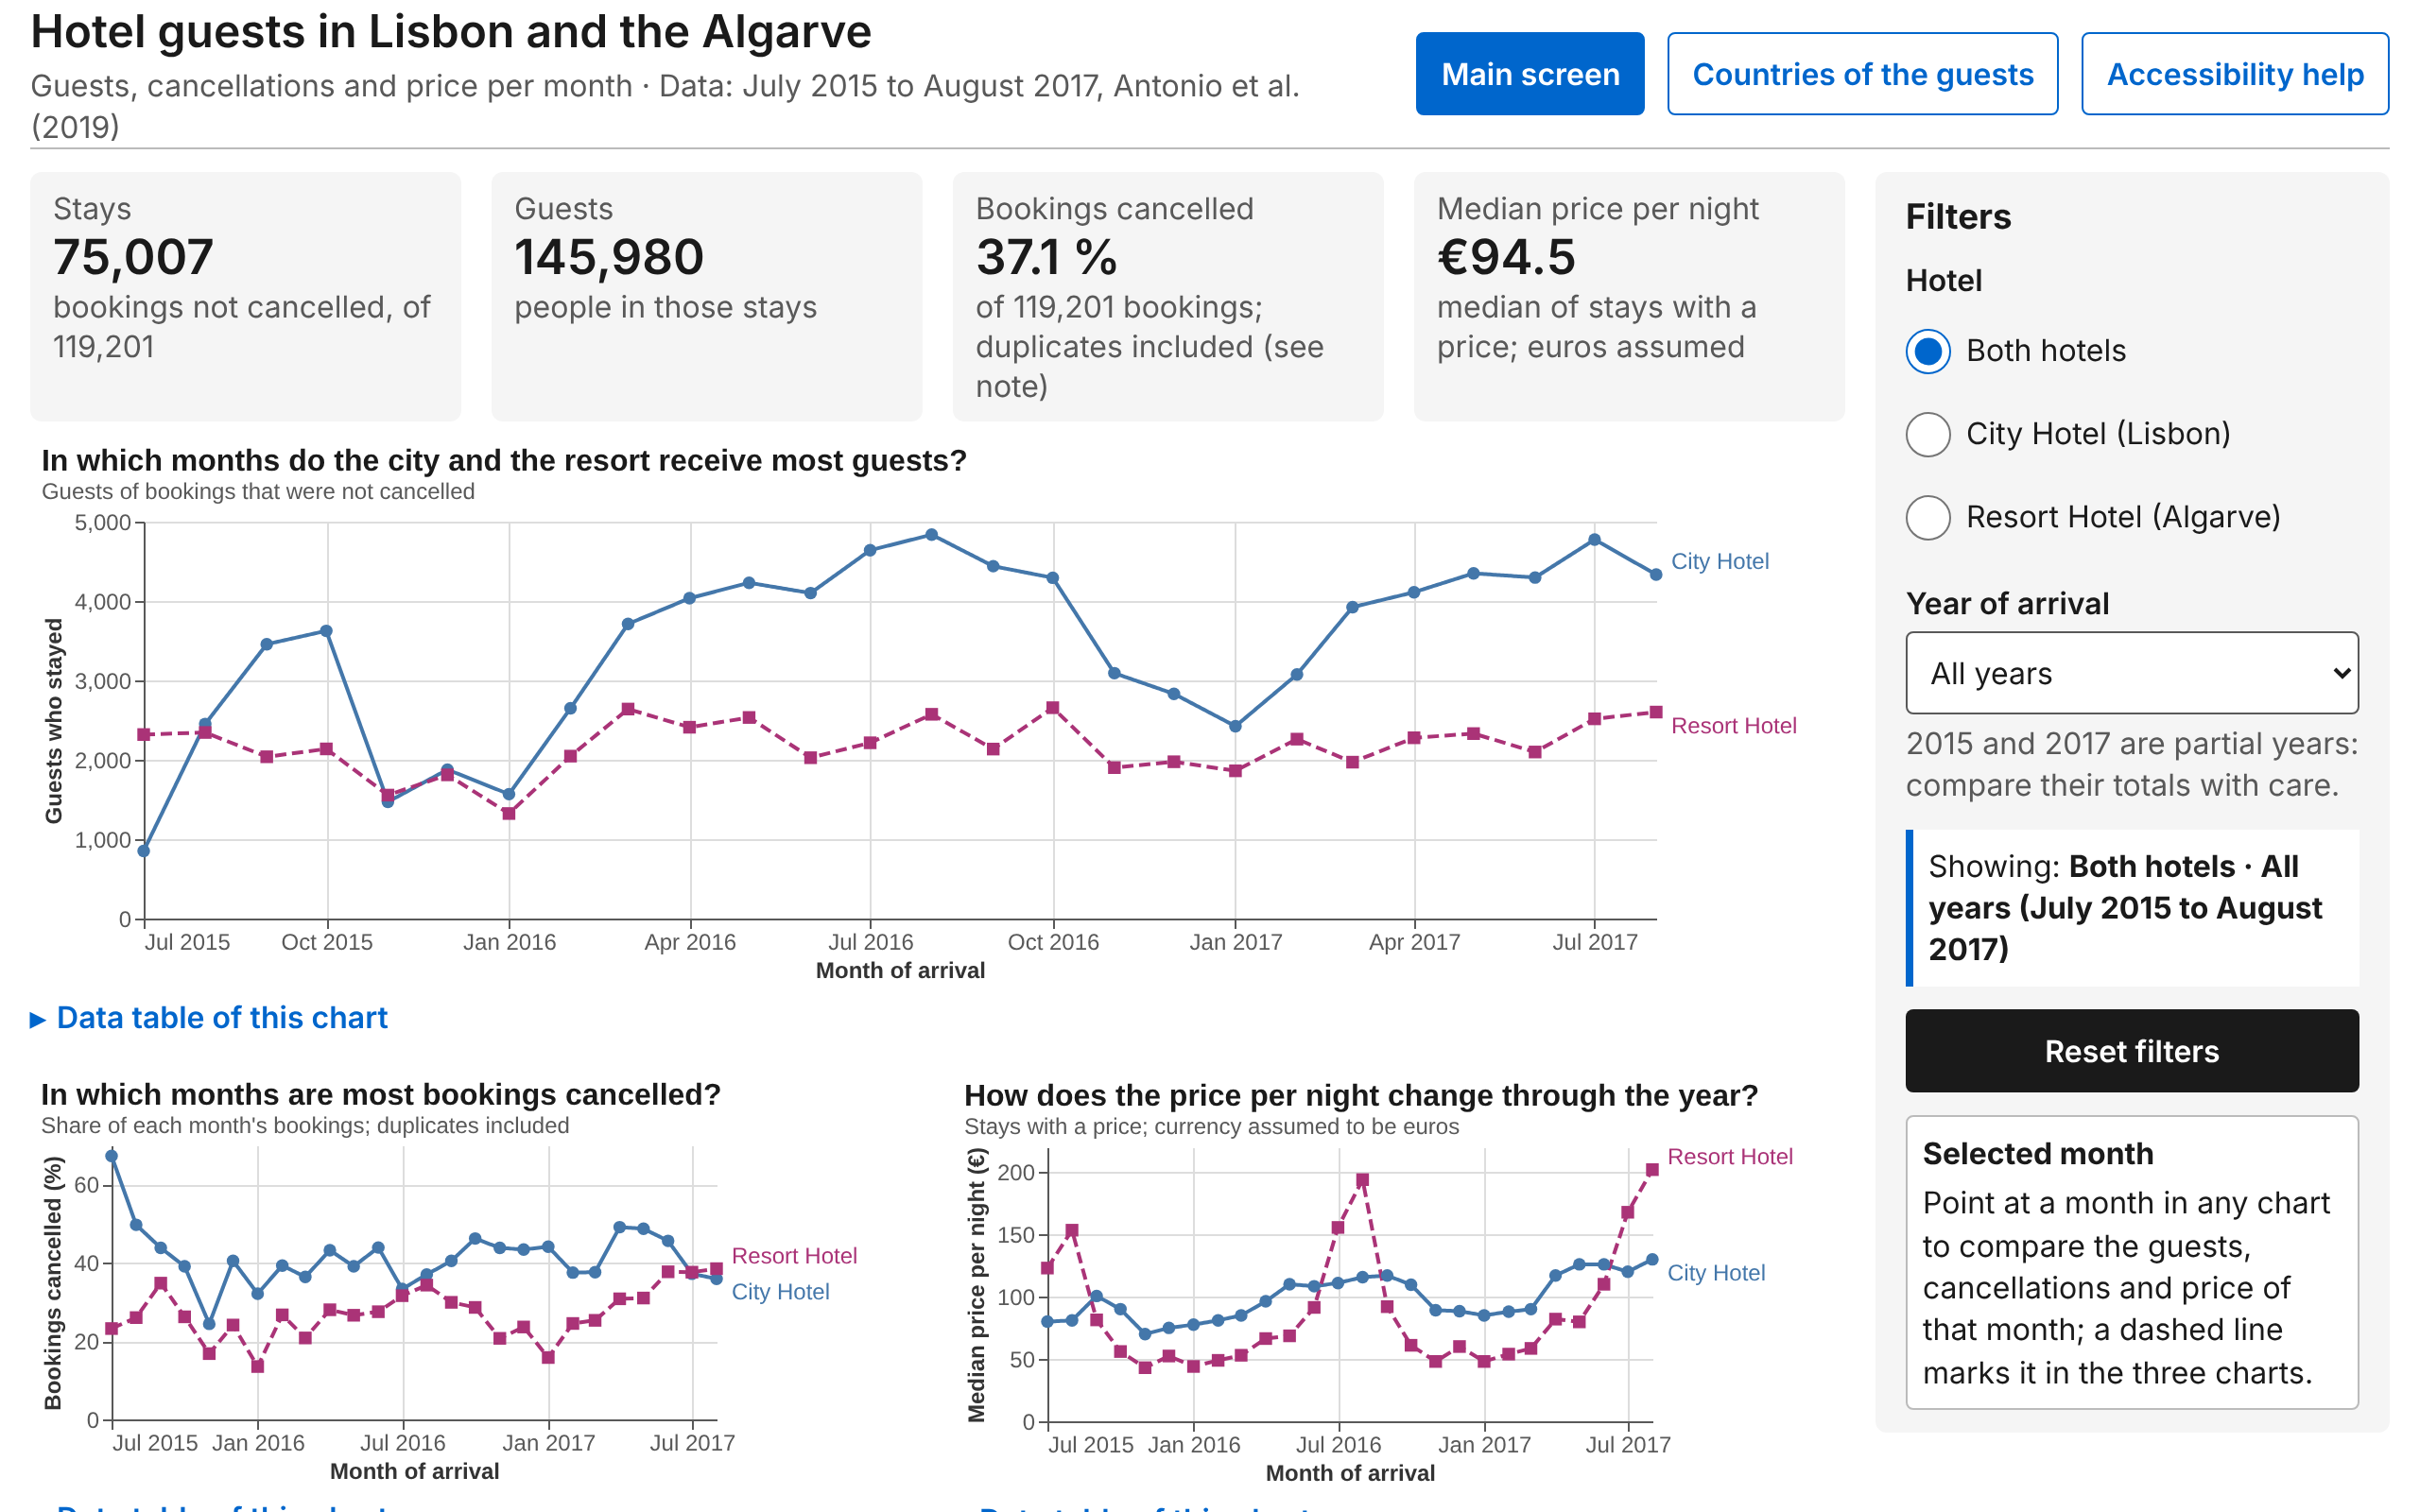

Main screen used with the keyboard


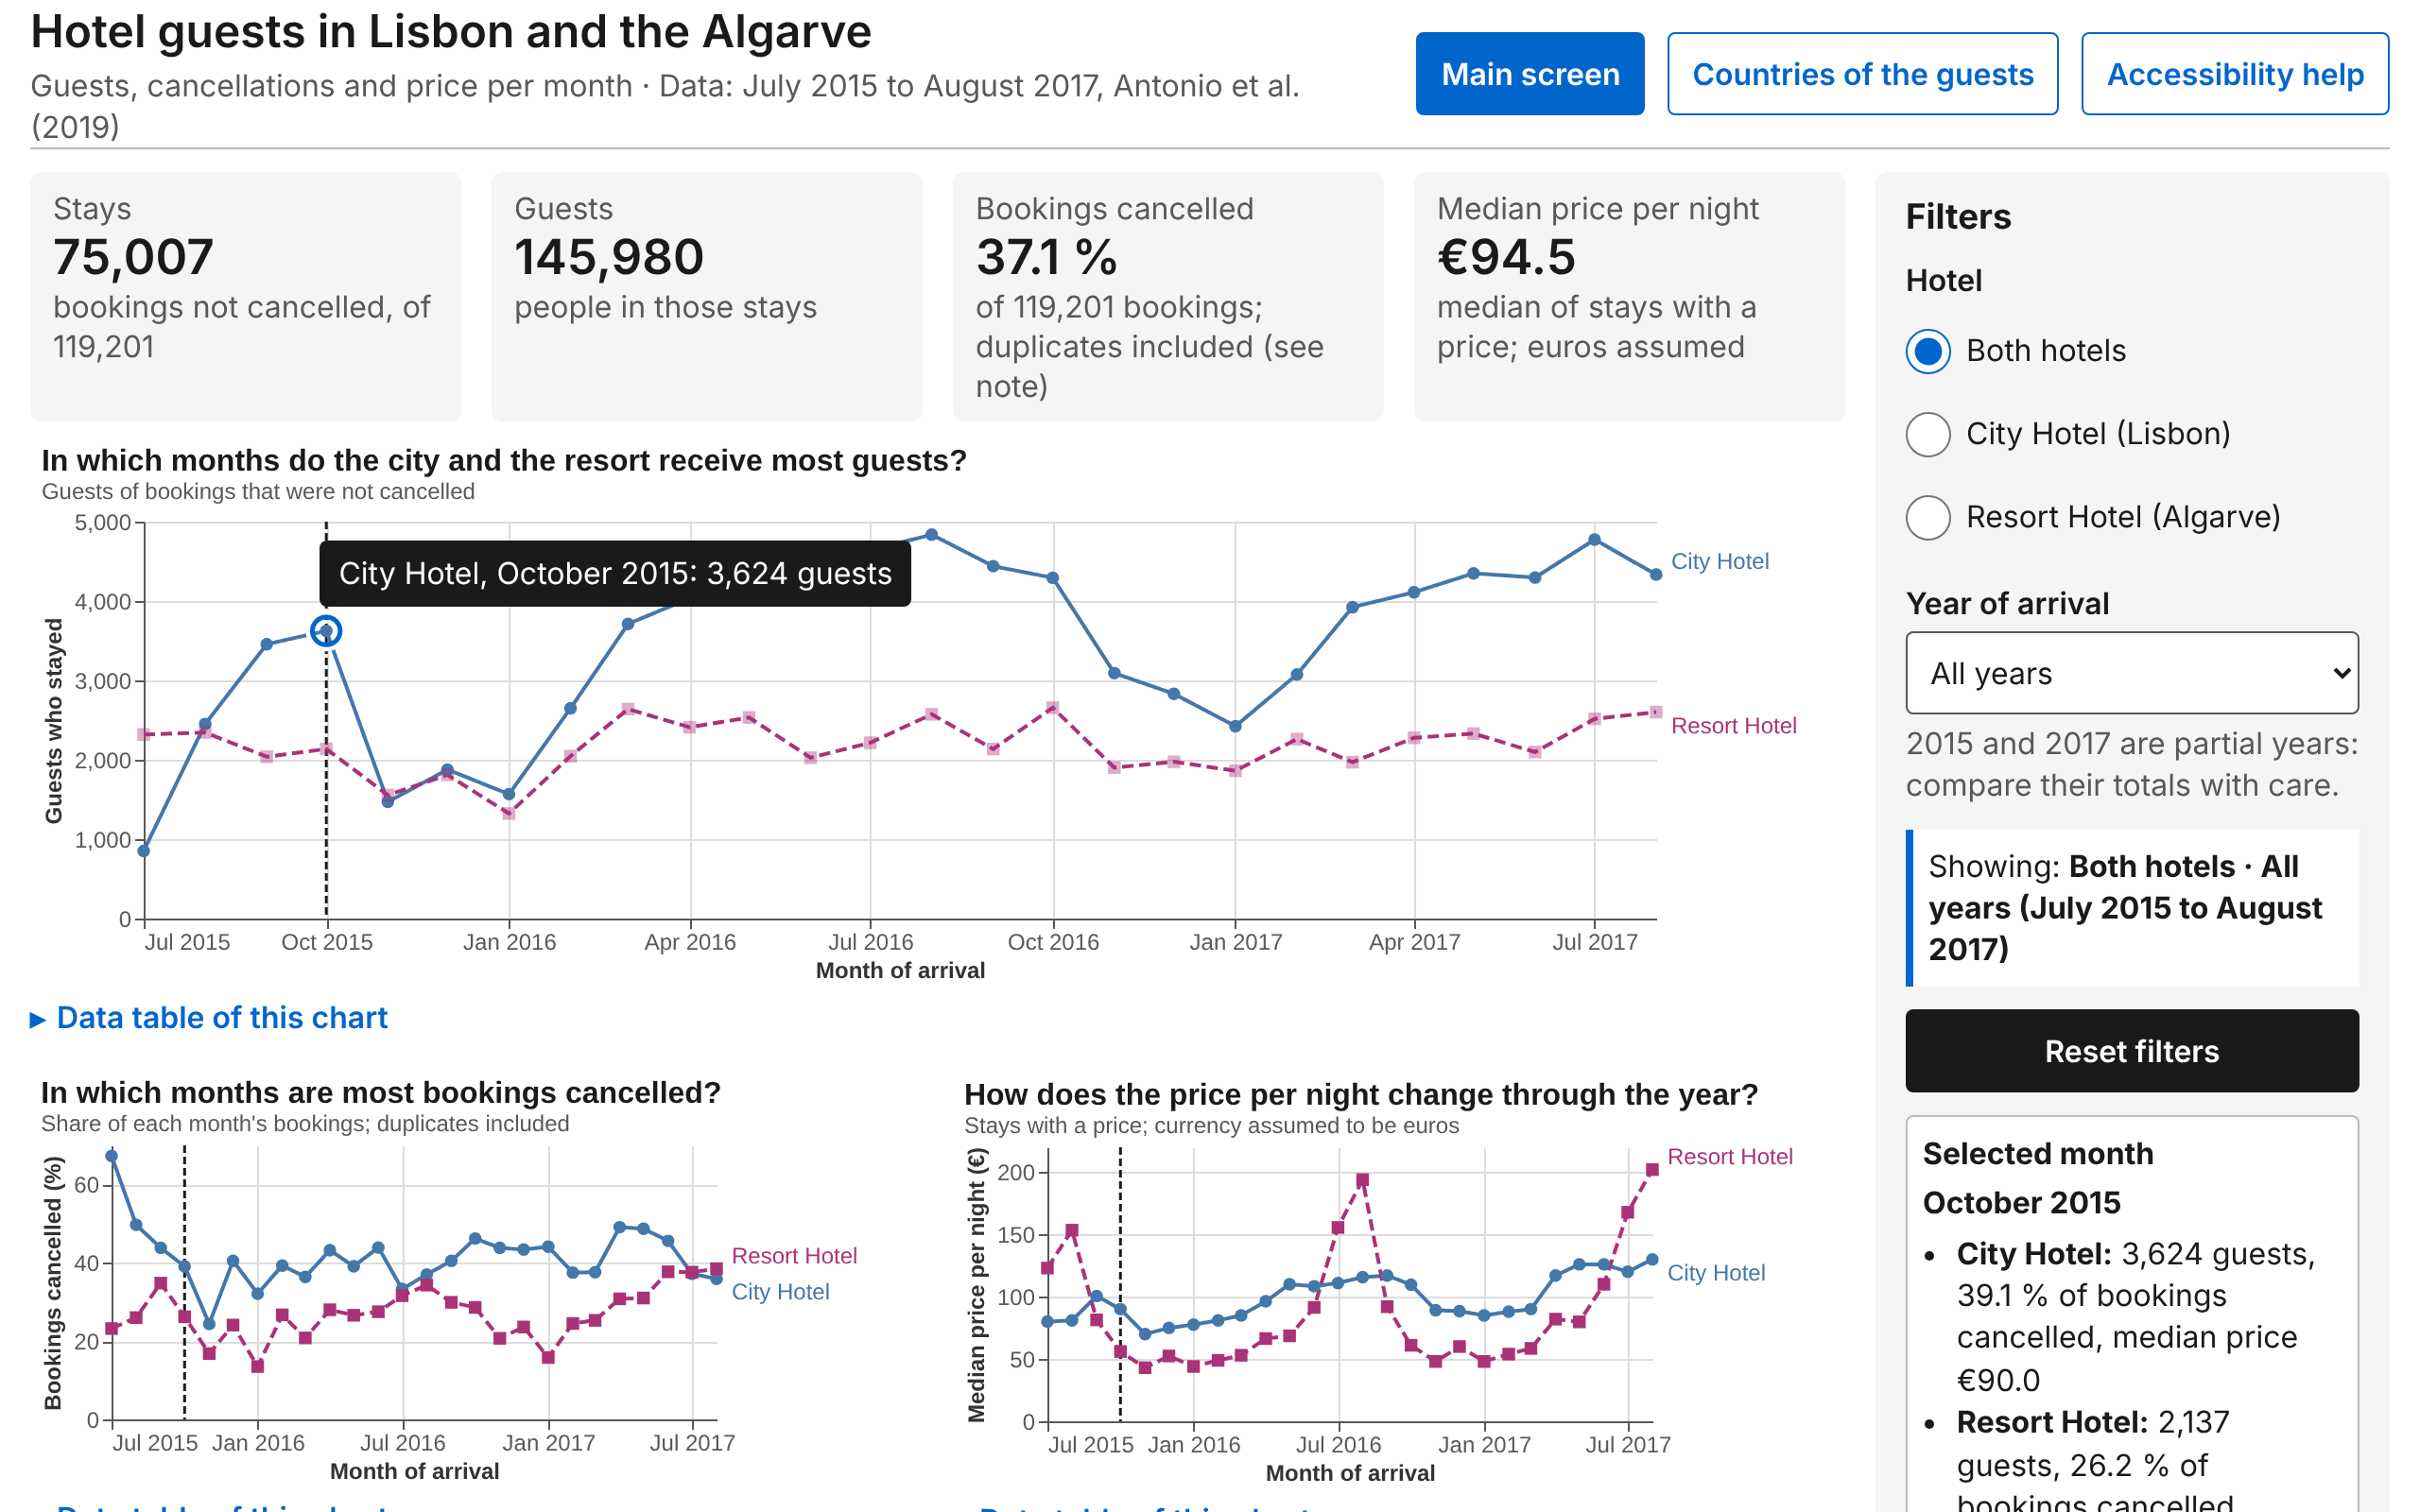

Detail screen at first load


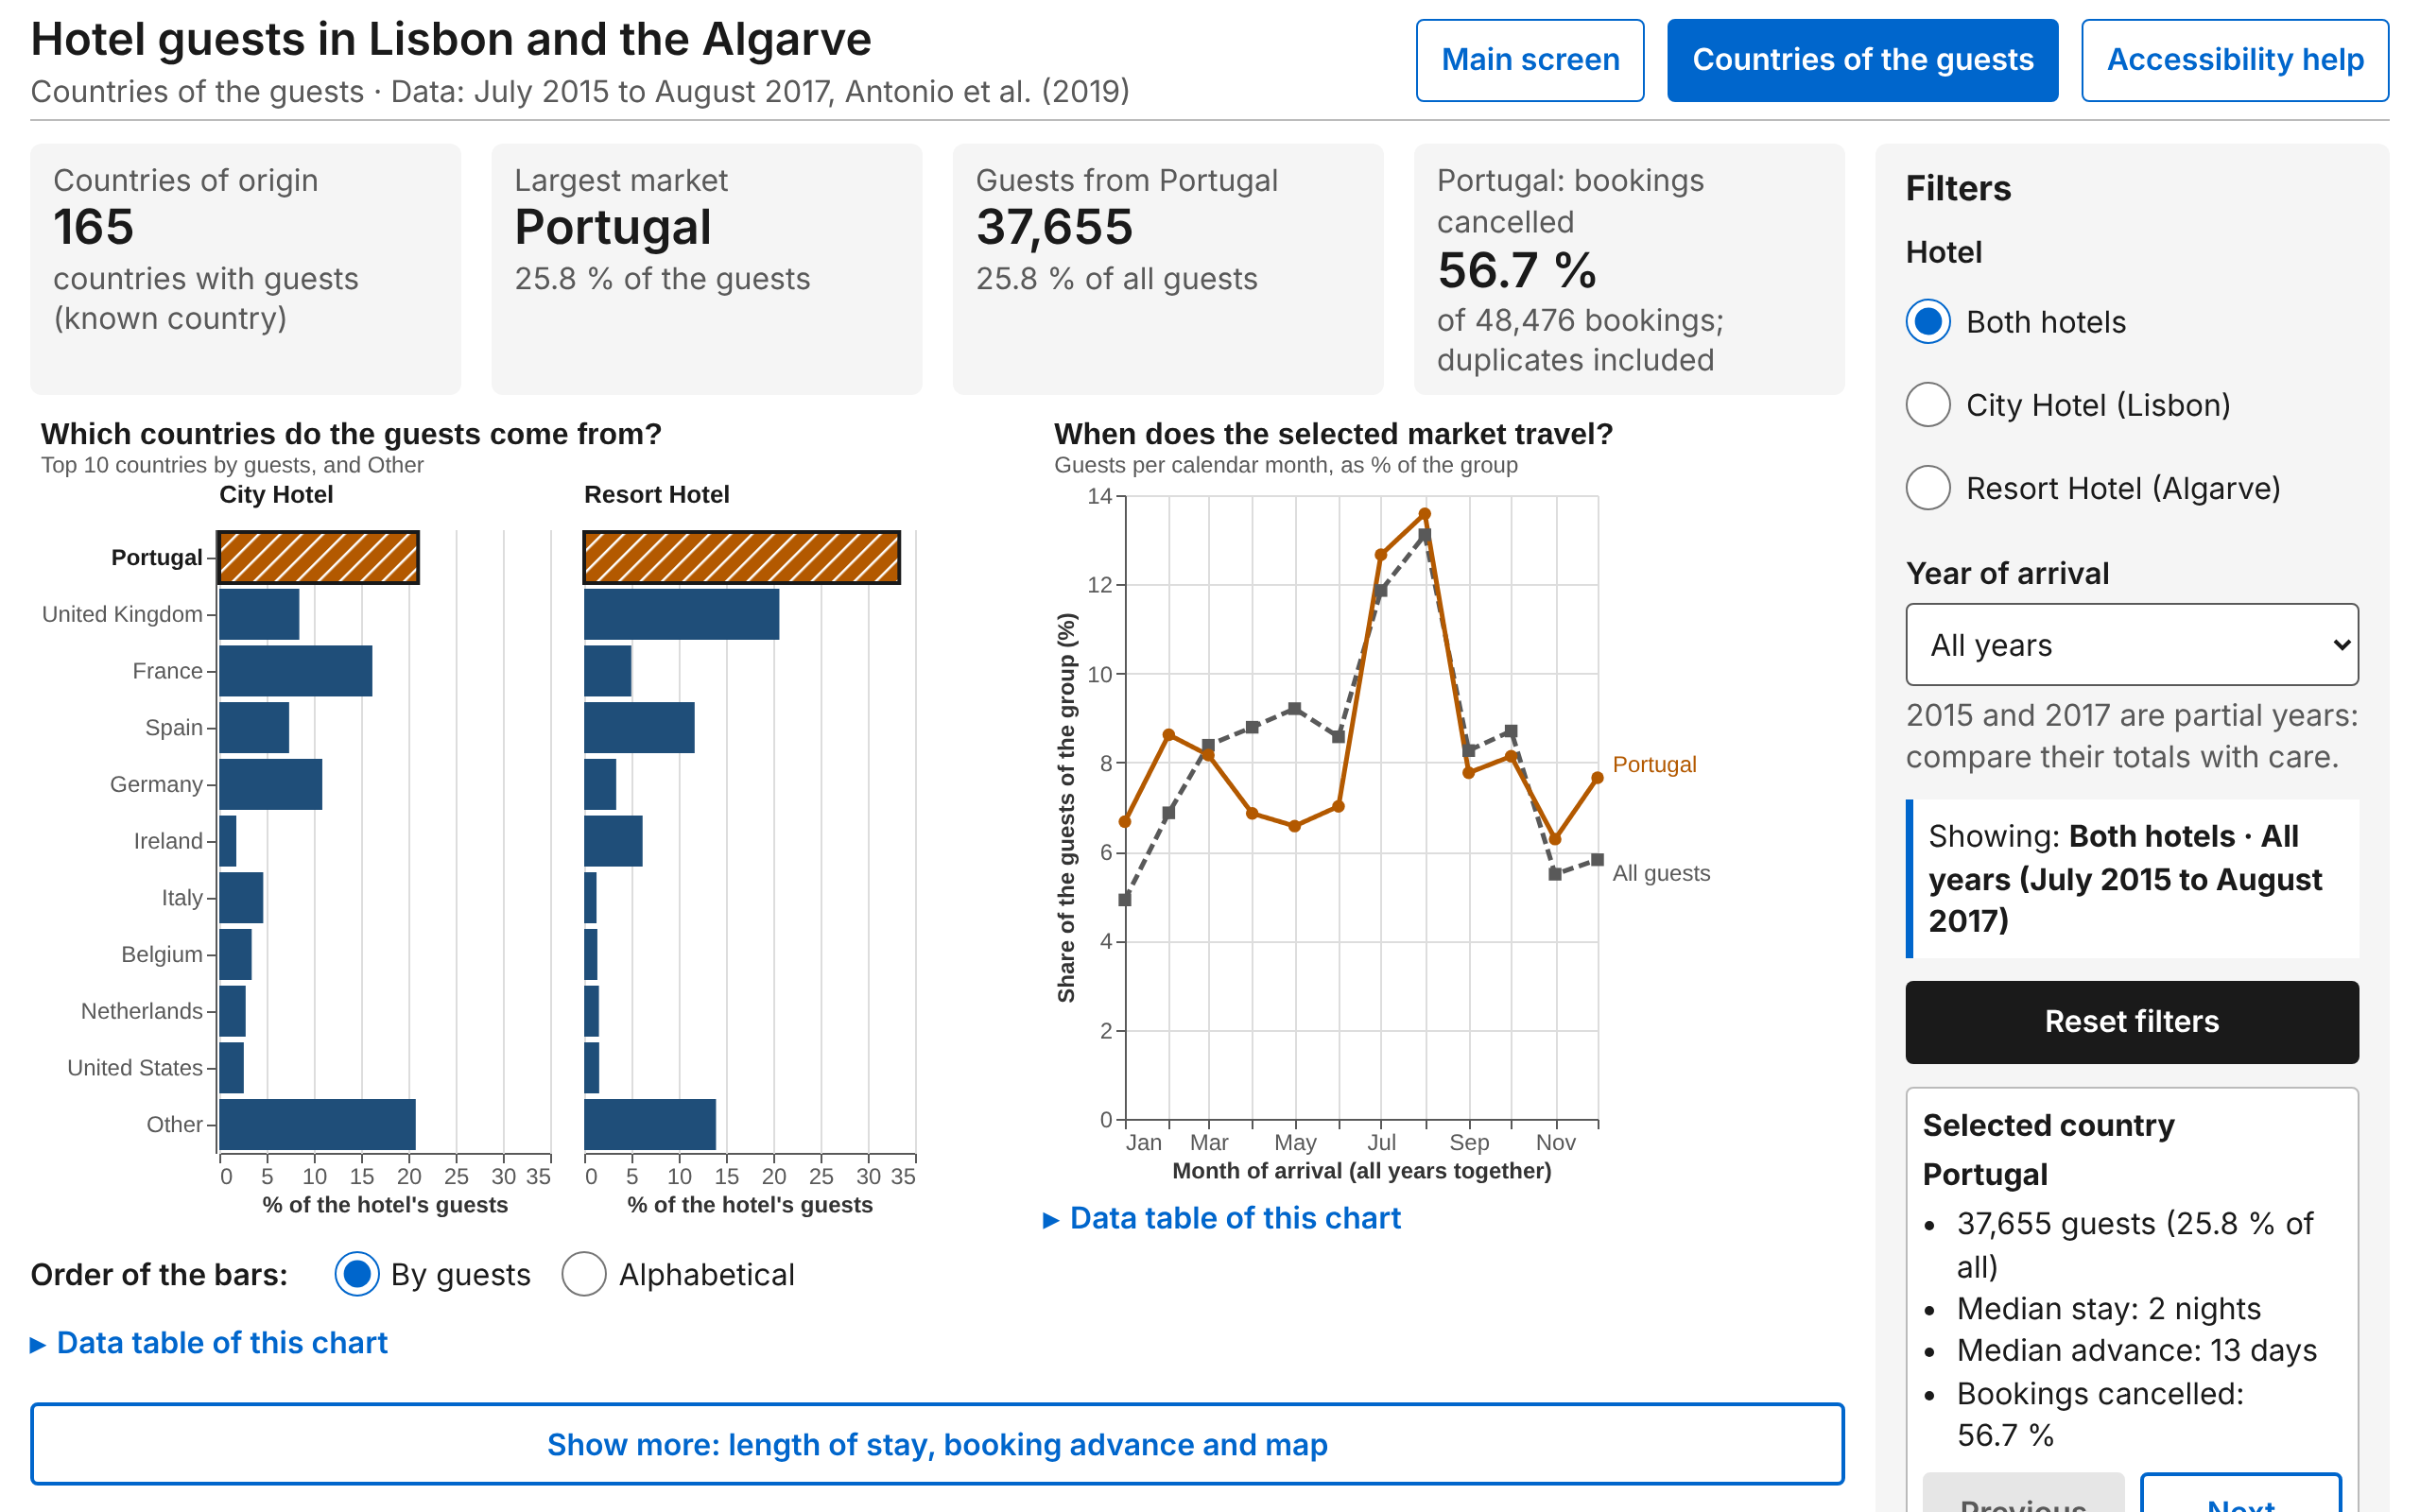

Detail screen with "Show more" open (whole page)


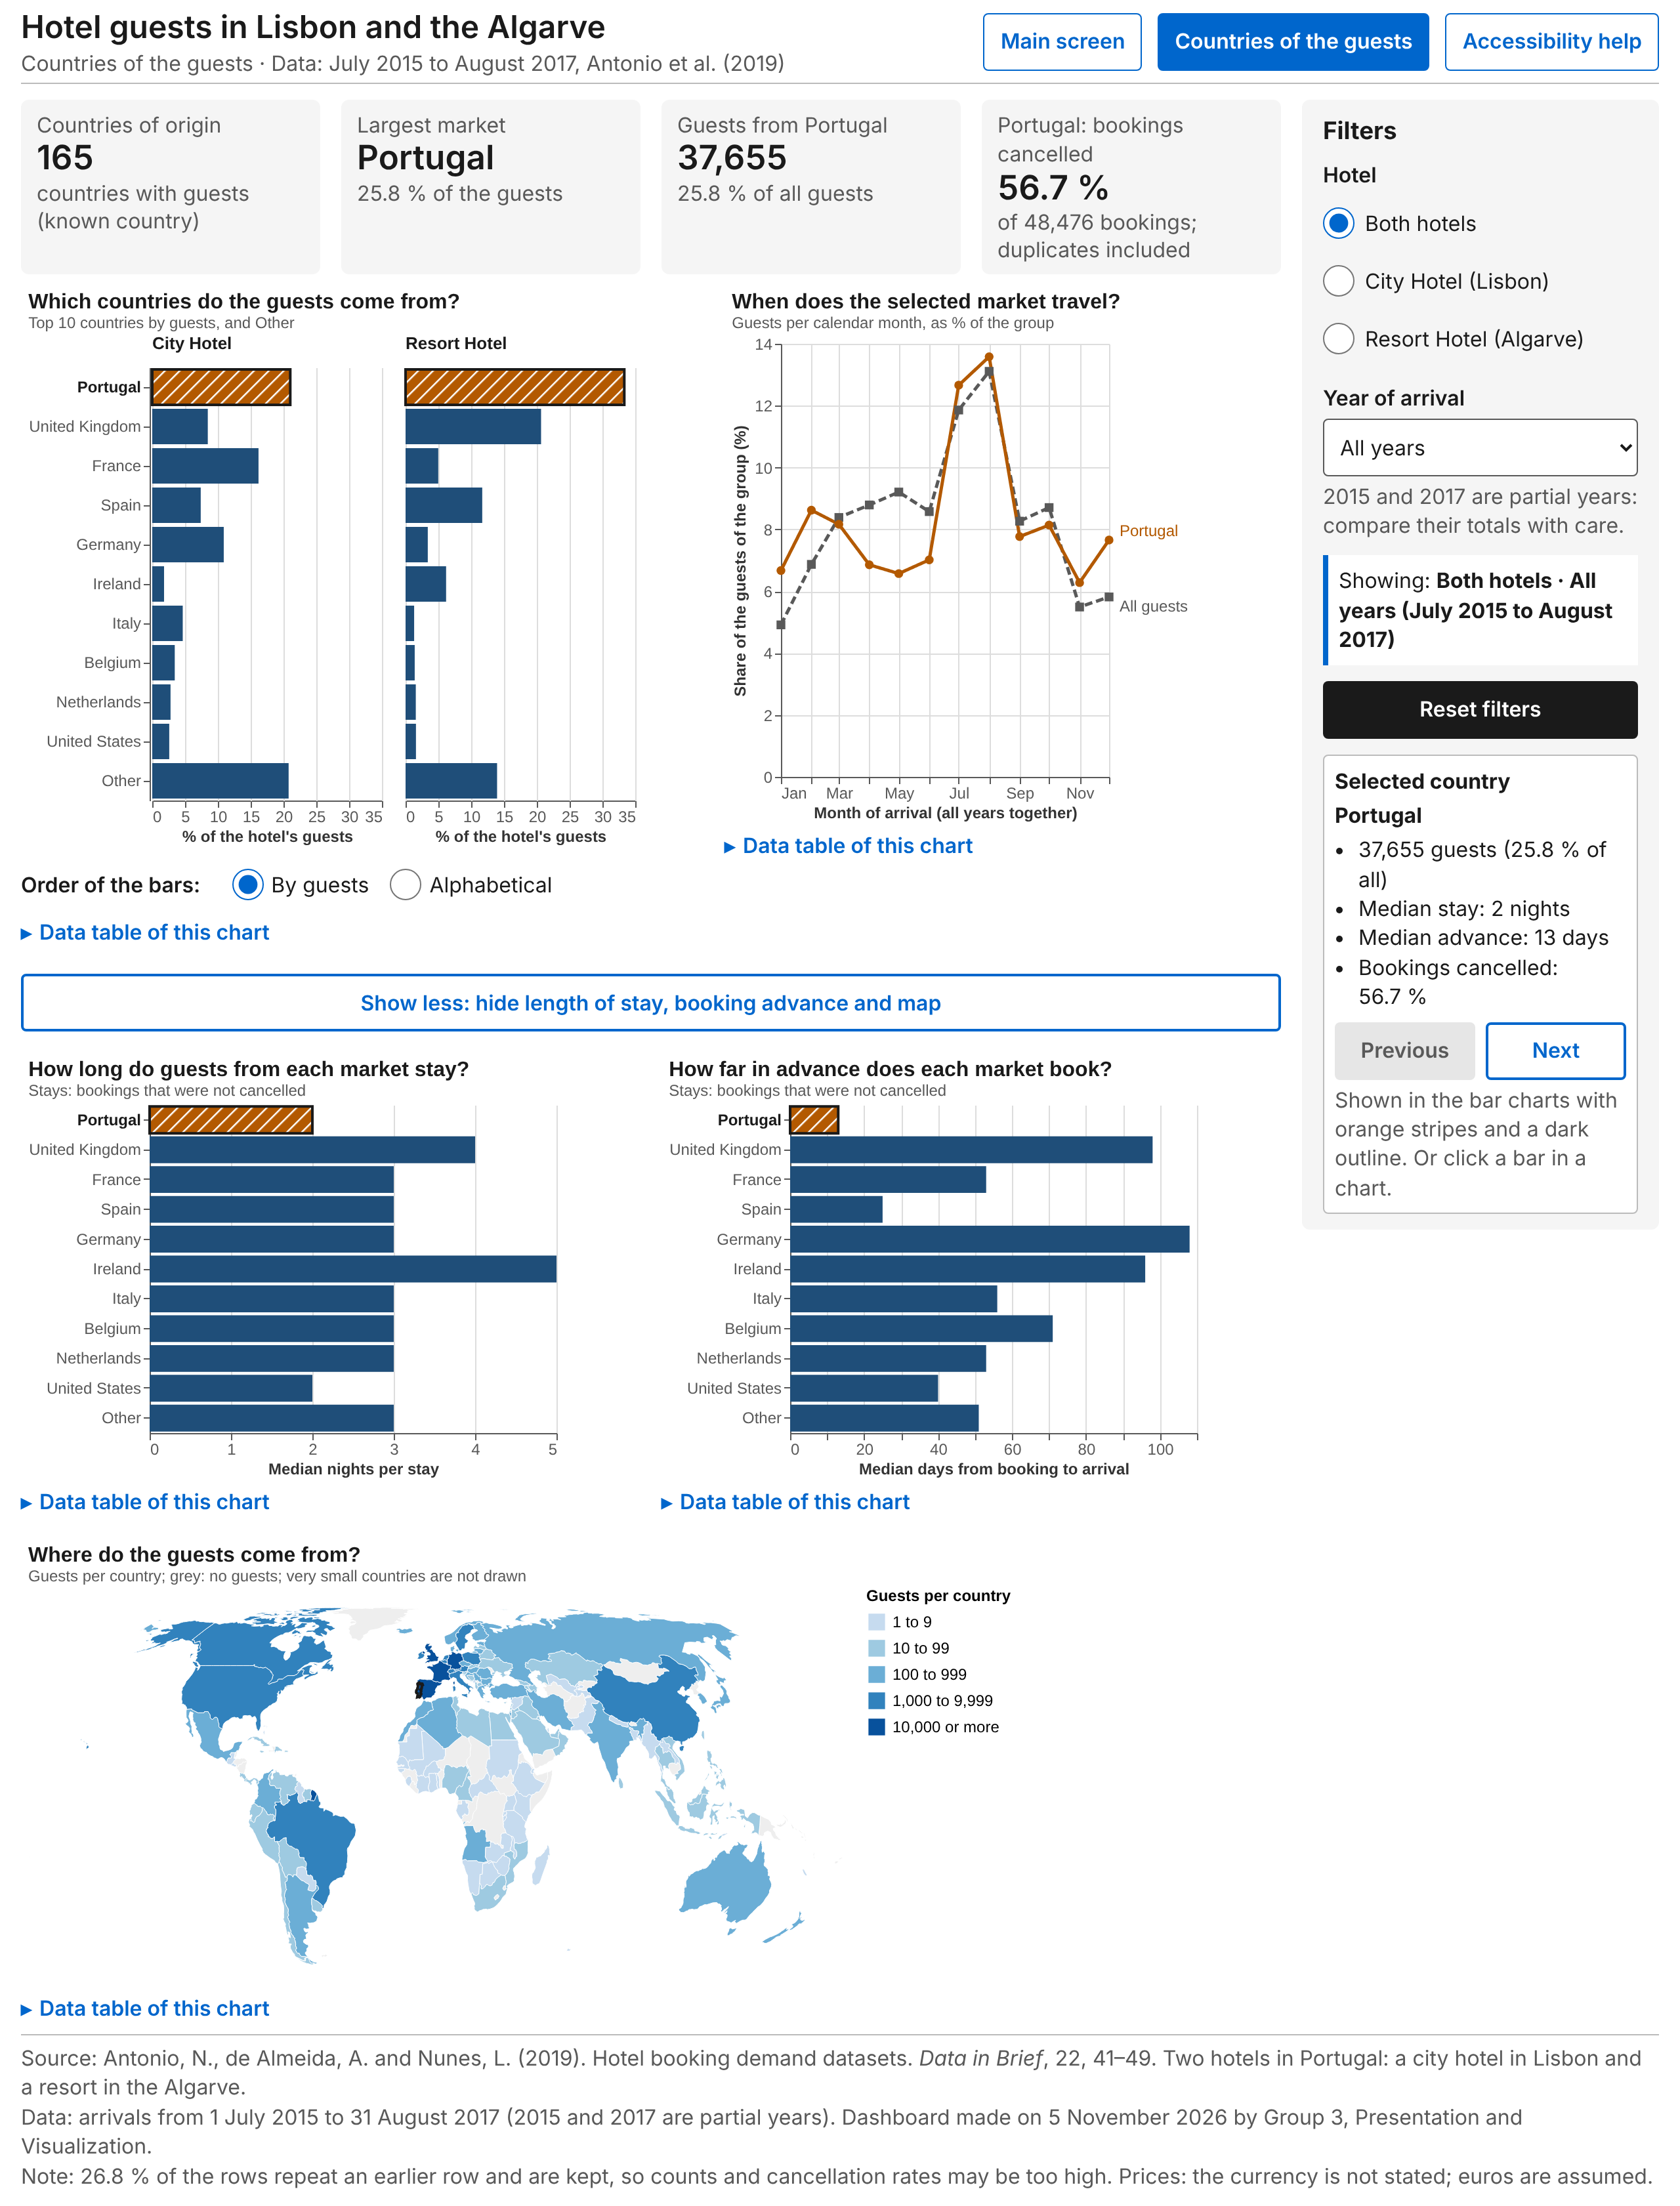

In [10]:
# ── Screenshots for the Part 6 document ──────────────────────────────────────
SCREEN = {'width': 1280, 'height': 800}
shots = []
async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    context = await browser.new_context(viewport=SCREEN, device_scale_factor=2)
    page = await context.new_page()

    await page.goto((DASHBOARD_DIR / 'index.html').as_uri())
    await page.wait_for_selector('body[data-dashboard-ready="true"]')
    await page.screenshot(path=IMAGES_DIR / 'main_screen.png')
    shots.append(('main_screen.png', 'Main screen at first load'))

    # Keyboard: Tab into C1, three right arrows (October 2015), as a keyboard user would
    for _ in range(6):
        await page.keyboard.press('Tab')
    for _ in range(3):
        await page.keyboard.press('ArrowRight')
    await page.wait_for_timeout(400)
    await page.screenshot(path=IMAGES_DIR / 'main_screen_keyboard.png')
    shots.append(('main_screen_keyboard.png', 'Main screen used with the keyboard'))

    await page.goto((DASHBOARD_DIR / 'detail.html').as_uri())
    await page.wait_for_selector('body[data-dashboard-ready="true"]')
    await page.screenshot(path=IMAGES_DIR / 'detail_screen.png')
    shots.append(('detail_screen.png', 'Detail screen at first load'))

    await page.click('#show-more')
    await page.wait_for_timeout(400)
    await page.screenshot(path=IMAGES_DIR / 'detail_screen_show_more.png', full_page=True)
    shots.append(('detail_screen_show_more.png', 'Detail screen with "Show more" open (whole page)'))
    await context.close()
    await browser.close()

from IPython.display import Image, display
for file_name, what in shots:
    print(what)
    display(Image(filename=IMAGES_DIR / file_name, width=640))

## 6. Export

In [11]:
# ── Export the review tables ──────────────────────────────────────────────────
hard.to_csv(OUTPUT_DIR / 'draco_hard_rules_by_chart.csv', index=False)
soft.to_csv(OUTPUT_DIR / 'draco_checklist.csv', index=False)
dataviz.to_csv(OUTPUT_DIR / 'dataviz_checklist.csv', index=False)
notebook_review.to_csv(OUTPUT_DIR / 'notebook_checklist.csv')
other_items.to_csv(OUTPUT_DIR / 'notebook_checklist_other_items.csv', index=False)
wcag.to_csv(OUTPUT_DIR / 'wcag_checklist.csv', index=False)
open_items.to_csv(OUTPUT_DIR / 'open_items.csv', index=False)
pd.DataFrame(shots, columns=['image', 'what']).to_csv(OUTPUT_DIR / 'screenshots.csv', index=False)
sorted(path.name for path in OUTPUT_DIR.iterdir()) + sorted(path.name for path in IMAGES_DIR.glob('*.png'))

['dataviz_checklist.csv',
 'draco_checklist.csv',
 'draco_hard_rules_by_chart.csv',
 'notebook_checklist.csv',
 'notebook_checklist_other_items.csv',
 'open_items.csv',
 'screenshots.csv',
 'wcag_checklist.csv',
 'detail_screen.png',
 'detail_screen_show_more.png',
 'main_screen.png',
 'main_screen_keyboard.png']

## Conclusions

### Task 6.8 (screenshots and review)
1. Four screenshots of the two screens are in `../images/` for the Part 6 document.
2. DRACO: every hard rule passes on every chart (checked by code on the real specs); the map is outside DRACO and follows the GeoHandout.
3. Data-viz and notebook checklists: met, with two adaptations decided in architecture.md (computer or tablet only; `data.js` instead of `data.json`).
4. WCAG 2.2 AA + COGA: met, with the adaptations and the open items listed in section 4.5 for the students.
5. The students approved the review and asked for two changes, both made before these screenshots: every page text is now at least 16 px (the Part 4 plan), and the screen links in the header keep one line.

### Limitations
- The screenshots and checks come from headless Chromium; the students should look at both screens in their own browser.

### Next steps
- Task 6.9: the Part 6 document (`.md` and `.pdf`).